# Experiment B: Shared LDA topics and clause-level aspect sentiment

**Research question.** Which themes appear in Vietnamese hotel reviews, and how do guests evaluate each aspect when it is actually mentioned? This notebook fits **one LDA model on all reviews**, then compares a common topic space across rating groups. It separately identifies aspect mentions and polarity in short review clauses. Overall Agoda rating is used only for the final group comparison, never as a clause-sentiment label.

**Input and output.** Read only `data/agoda_vi_reviews_preprocessed.csv`; charts and tables are embedded in this notebook. No new dataset CSV is created. `lda_text` is used only for topic discovery. `review_text_normalized` is used for clause-level analysis because it still contains negation and sentence context. Run all cells in order with the `.venv` kernel after installing `requirements-experiments.txt`.

**Important scope.** The aspect and sentiment stage below is an explicit, auditable **rule-based exploratory method**, not a trained or validated ABSA model. It produces candidate findings and an audit sample; a manually labeled holdout is needed before accuracy claims. The [VLSP 2018 Vietnamese hotel ABSA task](https://vlsp.org.vn/node/82) formalizes aspect–polarity pairs, and [SemEval-2014 Task 4](https://aclanthology.org/S14-2004/) separates aspect detection from polarity classification.


## 1. Set up libraries, paths, and modeling choices

The search explores K = 4, 6, 8, 10, 12, broader than the paper's K = 1–6 because this is one model for all review groups. The vocabulary filter removes rare spellings and extremely frequent tokens. The model uses a fixed seed, two passes, and a fixed coherence sample. These are reproducible implementation settings; topic quality still needs human reading.


In [12]:
import csv
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/agoda_vi_reviews_preprocessed.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Missing preprocessed CSV")
INPUT = ROOT / "data/agoda_vi_reviews_preprocessed.csv"
GROUPS = ("Detractors", "Passives", "Promoters")
GROUP_COLORS = {"Detractors": "#c44e52", "Passives": "#ddaa33", "Promoters": "#4c9f70"}
SEED, K_VALUES, PASSES, ITERATIONS = 42, (4, 6, 8, 10, 12), 2, 40
COHERENCE_SAMPLE, TOP_N = 3000, 15
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Input:", INPUT)
print("Candidate K:", K_VALUES)


Input: /home/tvphuoc/NLP/data/agoda_vi_reviews_preprocessed.csv
Candidate K: (4, 6, 8, 10, 12)


## 2. Load the complete Vietnamese review corpus

Read every row with nonempty `lda_text` and a normalized review. The rating-derived groups are metadata for later comparison. Check counts and a few structural properties before training. The group-size chart reminds us that raw counts are not comparable without denominators.


Reviews: 87837 Groups: {'Promoters': 57255, 'Passives': 12462, 'Detractors': 18120}


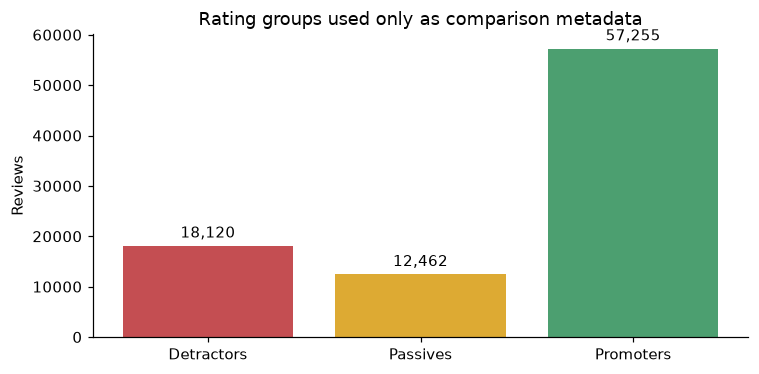

In [13]:
with INPUT.open("r", encoding="utf-8", newline="") as stream:
    reader = csv.DictReader(stream)
    required = {"hotel_id", "review_id", "label", "lda_text", "review_text_normalized"}
    missing = required - set(reader.fieldnames or [])
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    rows = [r for r in reader if r["lda_text"].strip() and r["review_text_normalized"].strip()]
if any(r["label"] not in GROUPS for r in rows):
    raise ValueError("Unexpected rating group")
texts = [r["lda_text"].split() for r in rows]
group_sizes = Counter(r["label"] for r in rows)
print("Reviews:", len(rows), "Groups:", dict(group_sizes))
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(GROUPS, [group_sizes[g] for g in GROUPS],
              color=[GROUP_COLORS[g] for g in GROUPS])
ax.bar_label(bars, labels=[f"{group_sizes[g]:,}" for g in GROUPS], padding=3)
ax.set(ylabel="Reviews", title="Rating groups used only as comparison metadata")
plt.tight_layout(); plt.show()


## 3. Build one shared LDA vocabulary and search K

A **single** dictionary gives every group the same topic definitions. Filter tokens below 20 document occurrences or above 60% document prevalence; keep at most 10,000 terms. Remove reviews that become empty after this filter for the LDA fit only. Every K is trained on the same full filtered corpus. C_v coherence uses a fixed random sample of up to 3,000 documents and the top 15 topic words. Record the coherence winner, then use K=8 for the downstream interpretation on this snapshot: the K=4 winner merges room, service, and location into a broad cluster, while K=8 separates recurring service themes more clearly. This documented human-interpretability choice is not presented as a coherence optimum. This cell may take several minutes.


In [14]:
dictionary = Dictionary(texts)
dictionary.filter_extremes(no_below=20, no_above=0.60, keep_n=10000)
bows = [dictionary.doc2bow(tokens) for tokens in texts]
lda_indices = [i for i, bow in enumerate(bows) if bow]
corpus = [bows[i] for i in lda_indices]
lda_texts = [texts[i] for i in lda_indices]
if len(dictionary) < 30 or len(corpus) < 100:
    raise ValueError("Insufficient corpus for LDA")
print("Usable LDA documents:", len(corpus), "Vocabulary:", len(dictionary),
      "Empty after vocabulary filtering:", len(rows) - len(corpus))
sample = random.Random(SEED).sample(lda_texts, min(COHERENCE_SAMPLE, len(lda_texts)))
models, scores = {}, {}
for k in K_VALUES:
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     passes=PASSES, iterations=ITERATIONS, chunksize=2000,
                     random_state=SEED, eval_every=None, minimum_probability=0)
    score = CoherenceModel(model=model, texts=sample, dictionary=dictionary,
                           coherence="c_v", topn=TOP_N, processes=1).get_coherence()
    models[k], scores[k] = model, float(score)
    print(f"K={k}: C_v={score:.4f}", flush=True)
COHERENCE_BEST_K = max(K_VALUES, key=lambda k: (scores[k], -k))
BEST_K = 8  # Human interpretation choice on this fixed snapshot; see the markdown above.
lda = models[BEST_K]
print(f"Coherence winner: K={COHERENCE_BEST_K}, C_v={scores[COHERENCE_BEST_K]:.4f}")
print(f"Model used downstream: K={BEST_K}, C_v={scores[BEST_K]:.4f}")


Usable LDA documents: 87540 Vocabulary: 1890 Empty after vocabulary filtering: 297
K=4: C_v=0.6006
K=6: C_v=0.5842
K=8: C_v=0.5693
K=10: C_v=0.5653
K=12: C_v=0.5503
Coherence winner: K=4, C_v=0.6006
Model used downstream: K=8, C_v=0.5693


## 4. Chart the coherence curve and read every topic

The curve shows both the coherence winner and the model chosen for interpretation. Coherence is not a complete measure of human interpretability: read the full top-word lists and real examples before treating a topic as a hotel aspect. Topic IDs are arbitrary model identifiers. Sentiment-like words can enter a topic even though LDA has no sentiment mechanism.


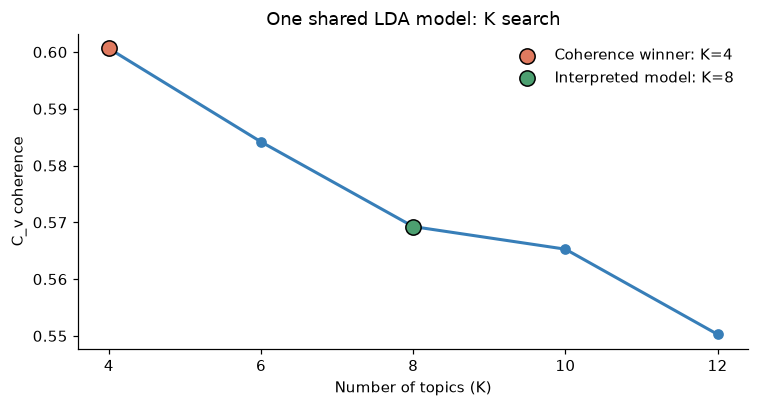

Topic 0 — Food and breakfast (provisional): sáng, ngon, món, đồ_ăn, ít, nhiều, bữa, buffet, nhà_hàng, khách_sạn, đẹp, hồ, đa_dạng, buổi, phong_phú
Topic 1 — Location and value (provisional): khách_sạn, vị_trí, đẹp, gần, phòng, trung_tâm, sạch_sẽ, biển, thuận_tiện, giá, hợp_lý, view, địa_điểm, giá_cả, tiện_nghi
Topic 2 — Booking and service issues (provisional): phòng, khách_sạn, khách, khi, nhân_viên, khác, sau, tệ, lễ_tân, hơn, người, tiền, đêm, agoda, h
Topic 3 — Room and amenities (provisional): phòng, cũ, nước, mùi, giường, nhỏ, nóng, khách_sạn, sạch, giá, ok, khăn, bẩn, máy_lạnh, nhà_vệ_sinh
Topic 4 — Location and access (provisional): xe, ổn, biển, khách_sạn, chỗ, đường, bãi, gần, bên, tạm, đêm, phòng, bộ, điểm, nhỏ
Topic 5 — Overall stay (provisional): gia_đình, nơi, thoải_mái, không_gian, khi, nhà, người, nhiều, tuyệt_vời, trải_nghiệm, sự, nhỏ, phòng, khu, chuyến
Topic 6 — Staff and cleanliness (provisional): nhân_viên, sạch_sẽ, nhiệt_tình, phòng, khách_sạn, thân_thiện, dễ_thươ

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(K_VALUES, [scores[k] for k in K_VALUES], marker="o", color="#377eb8", linewidth=2)
ax.scatter(COHERENCE_BEST_K, scores[COHERENCE_BEST_K], s=100, color="#e07a5f", edgecolor="black", zorder=4, label=f"Coherence winner: K={COHERENCE_BEST_K}")
ax.scatter(BEST_K, scores[BEST_K], s=100, color="#4c9f70", edgecolor="black", zorder=4, label=f"Interpreted model: K={BEST_K}")
ax.set(xlabel="Number of topics (K)", ylabel="C_v coherence",
       title="One shared LDA model: K search")
ax.set_xticks(K_VALUES)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
# Provisional human labels were assigned after inspecting this snapshot's keywords
# and representative reviews; they are not automatic LDA sentiment predictions.
TOPIC_LABELS = {
    0: "Food and breakfast", 1: "Location and value",
    2: "Booking and service issues", 3: "Room and amenities",
    4: "Location and access", 5: "Overall stay",
    6: "Staff and cleanliness", 7: "Service quality and value",
}
for topic_id in range(BEST_K):
    words = ", ".join(word for word, _ in lda.show_topic(topic_id, topn=TOP_N))
    print(f"Topic {topic_id} — {TOPIC_LABELS[topic_id]} (provisional): {words}")


## 5. Inspect representative reviews and weighted topic words

Infer a topic distribution for every LDA-eligible review. Display the two reviews most strongly associated with each topic, then plot the top eight weighted terms for the six most prevalent topics. This supports manual naming of topics and helps identify mixed or incoherent clusters. A review can contribute to several topics; the dominant assignment is only for ranking examples and plotting.



Topic 0: 3,884 dominant reviews
  p=0.90: nội thất khách sạn mới, hiện đại. bữa sáng phong phú, hợp khẩu vị.
  p=0.89: cần cải thiện ăn sáng có phở cũng ngon hơn mì xào vào buổi sáng

Topic 1: 17,939 dominant reviews
  p=0.95: - khách sạn giá rẻ mà ngay trung tâm phố cổ hà nội, đầy đủ tiện nghi, gần khu ẩm thực hà nội - di chuyến tiện lợi các điểm như lăng bác, hồ hoàn kiếm,...
  p=0.95: vị trí cực kỳ thuận tiện, gần quảng trường, gần biển,gần nhiều quán ăn,siêu thị,..phòng rất sạch đẹp,giá cả hợp lý. bạn nào thích đi dạo biển,thích ăn uống thì khách sạn là lựa chọn hợp lý nhất

Topic 2: 14,975 dominant reviews
  p=0.98: tối có đặt 1 phòng trên agoda, đã thanh toán bên agoda, đến lúc nhận phòng thì chủ khách sạn bảo là hết phòng. vào chiều hôm ngày 10/8 mình có đặt phòng bên agoda, vì lí do nhầm ngày mình muốn huỷ, khách sạn bảo là liên 
  p=0.98: đặt 2 phòng đến khách sạn lúc khoảng 13h mình đi ô tô cá nhân đến nhưng không có 1 bảo vệ nào ra đón hành lý mà mình phải xuống xe gọi mời 

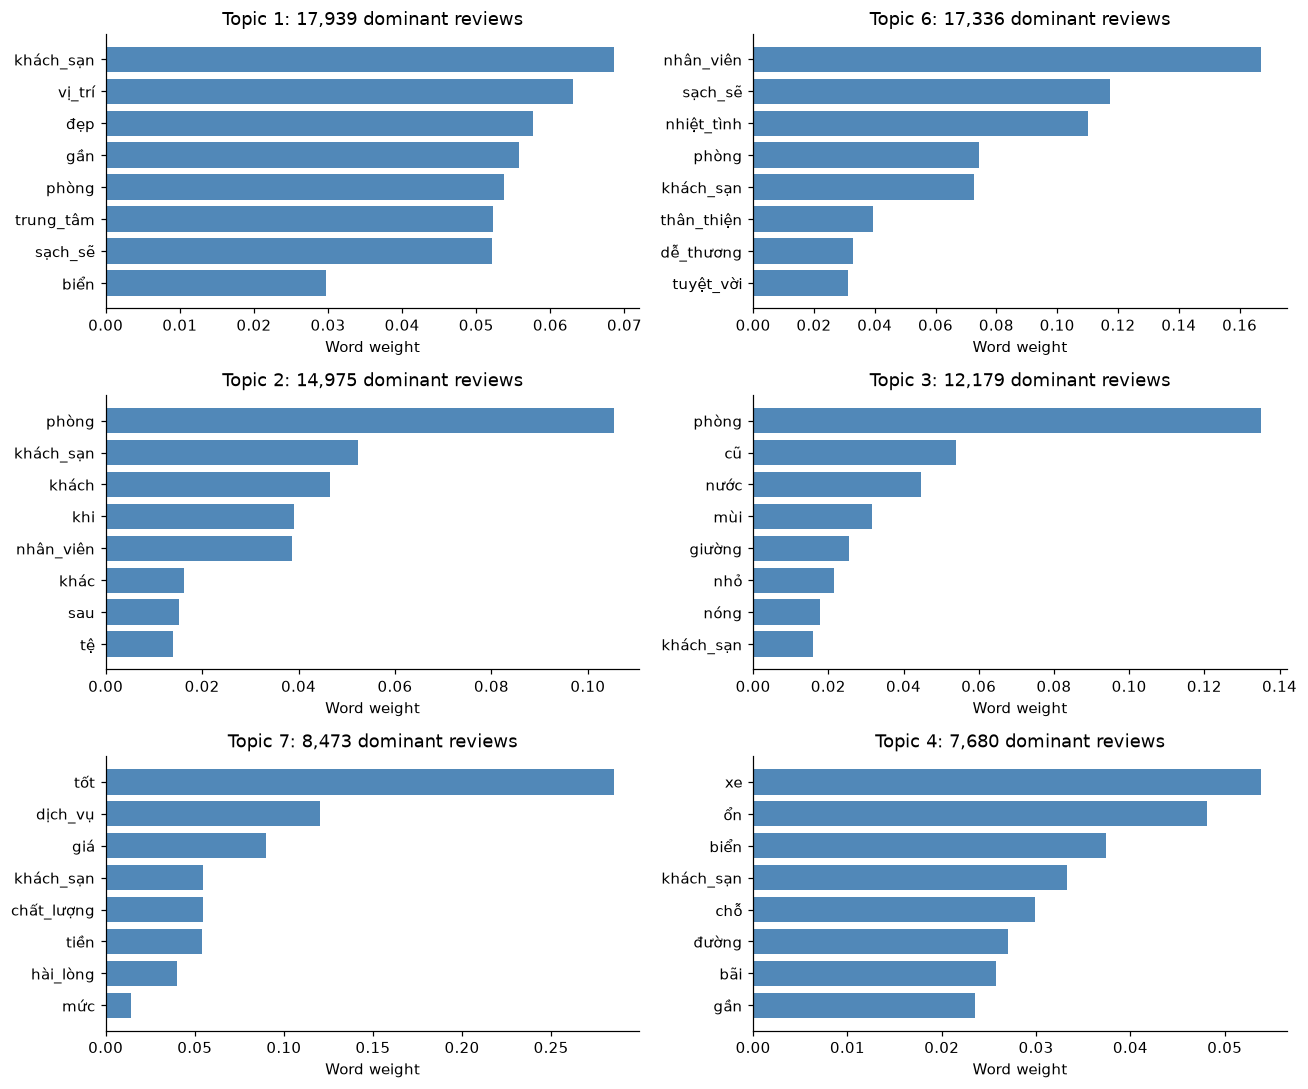

In [16]:
topic_counts = Counter()
examples = defaultdict(list)
mean_topic_sum = {g: np.zeros(BEST_K, dtype=float) for g in GROUPS}
mean_topic_n = Counter()
for bow, row_index in zip(corpus, lda_indices):
    distribution = lda.get_document_topics(bow, minimum_probability=0)
    weights = np.array([weight for _, weight in distribution])
    group = rows[row_index]["label"]
    mean_topic_sum[group] += weights
    mean_topic_n[group] += 1
    topic_id = int(np.argmax(weights))
    topic_counts[topic_id] += 1
    examples[topic_id].append((float(weights[topic_id]), rows[row_index]["review_text_normalized"]))
for topic_id in range(BEST_K):
    print(f"\nTopic {topic_id}: {topic_counts[topic_id]:,} dominant reviews")
    for probability, review in sorted(examples[topic_id], reverse=True)[:2]:
        print(f"  p={probability:.2f}: {review[:220]}")

popular_topics = [i for i, _ in topic_counts.most_common(6)]
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, topic_id in zip(axes.flat, popular_topics):
    pairs = lda.show_topic(topic_id, topn=8)[::-1]
    ax.barh([word for word, _ in pairs], [weight for _, weight in pairs], color="#5188b8")
    ax.set(title=f"Topic {topic_id}: {topic_counts[topic_id]:,} dominant reviews",
           xlabel="Word weight")
for ax in list(axes.flat)[len(popular_topics):]:
    ax.axis("off")
plt.tight_layout(); plt.show()


## 6. Compare the **same** topics across rating groups

Unlike three separate LDA models, this shared topic space supports a direct descriptive comparison. Each heatmap cell is the group's mean posterior probability for a topic, averaged over its reviews. A high value means the topic is more prevalent in that group, **not** that the topic is positive or negative. The group labels are derived from review ratings, not from the text's aspect polarity.


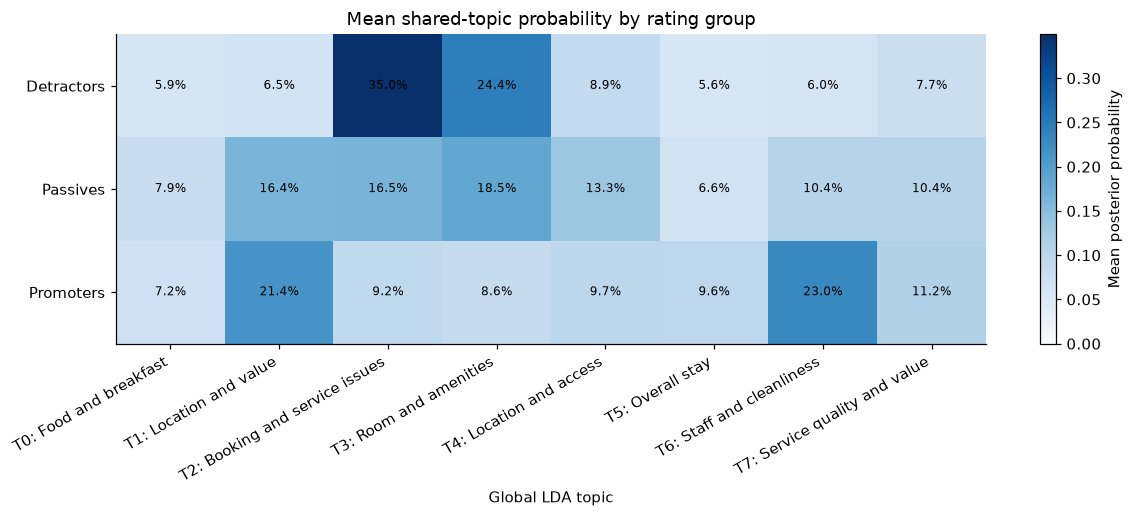

In [17]:
topic_matrix = np.vstack([mean_topic_sum[g] / mean_topic_n[g] for g in GROUPS])
fig, ax = plt.subplots(figsize=(max(10, BEST_K * 1.4), 4.8))
image = ax.imshow(topic_matrix, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(BEST_K), [f"T{i}: {TOPIC_LABELS[i]}" for i in range(BEST_K)], rotation=30, ha="right")
ax.set_yticks(range(len(GROUPS)), GROUPS)
for gi in range(len(GROUPS)):
    for ti in range(BEST_K):
        ax.text(ti, gi, f"{topic_matrix[gi, ti]:.1%}", ha="center", va="center", fontsize=8)
ax.set(title="Mean shared-topic probability by rating group", xlabel="Global LDA topic")
fig.colorbar(image, ax=ax, label="Mean posterior probability")
plt.tight_layout(); plt.show()


## 7. Define an explicit bridge from discovered themes to service aspects

After inspecting LDA keywords and representative reviews, use a **provisional, editable** aspect lexicon. The categories cover recurring themes such as location, staff, room comfort, cleanliness, food, facilities, and value. A topic can mix several of these; a topic ID is not automatically an aspect label. The terms below are a transparent manual interpretation layer and should be reviewed against the printed topic examples before final reporting. The original paper also relied on human topic naming. A clause may mention multiple aspects.


In [18]:
ASPECT_TERMS = {
    "Room comfort": ["phòng", "giường", "chăn", "gối", "phòng ốc", "cách âm", "diện tích", "view phòng"],
    "Cleanliness": ["sạch", "bẩn", "dơ", "vệ sinh", "mùi", "hôi", "ẩm mốc"],
    "Service": ["nhân viên", "lễ tân", "phục vụ", "bảo vệ", "chủ nhà", "dịch vụ", "thái độ"],
    "Location": ["vị trí", "địa điểm", "trung tâm", "gần biển", "bãi biển", "đường đi", "đi lại"],
    "Food": ["ăn sáng", "bữa sáng", "buffet", "đồ ăn", "món ăn", "thức ăn", "nhà hàng", "cà phê"],
    "Facilities": ["hồ bơi", "bể bơi", "thang máy", "wifi", "máy lạnh", "điều hòa", "bãi xe", "bãi đỗ", "spa", "tiện nghi", "nội thất"],
    "Value": ["giá", "tiền", "chi phí", "đáng tiền", "rẻ", "đắt", "mắc", "giá cả"],
}
print("Provisional aspects and number of lexical cues:")
for aspect, terms in ASPECT_TERMS.items():
    print(f"  {aspect}: {len(terms)} terms — {', '.join(terms[:5])}")

# Show how the manually curated aspect vocabulary relates to LDA top words.
for topic_id in range(BEST_K):
    topic_words = [w.replace("_", " ") for w, _ in lda.show_topic(topic_id, topn=TOP_N)]
    overlaps = {aspect: sum(any(term in word or word in term for term in terms)
                            for word in topic_words)
                for aspect, terms in ASPECT_TERMS.items()}
    ranked = sorted(overlaps.items(), key=lambda item: item[1], reverse=True)[:3]
    print(f"Topic {topic_id} ({TOPIC_LABELS[topic_id]}): likely aspects {ranked}")


Provisional aspects and number of lexical cues:
  Room comfort: 8 terms — phòng, giường, chăn, gối, phòng ốc
  Cleanliness: 7 terms — sạch, bẩn, dơ, vệ sinh, mùi
  Service: 7 terms — nhân viên, lễ tân, phục vụ, bảo vệ, chủ nhà
  Location: 7 terms — vị trí, địa điểm, trung tâm, gần biển, bãi biển
  Food: 8 terms — ăn sáng, bữa sáng, buffet, đồ ăn, món ăn
  Facilities: 11 terms — hồ bơi, bể bơi, thang máy, wifi, máy lạnh
  Value: 8 terms — giá, tiền, chi phí, đáng tiền, rẻ
Topic 0 (Food and breakfast): likely aspects [('Food', 6), ('Facilities', 1), ('Room comfort', 0)]
Topic 1 (Location and value): likely aspects [('Location', 5), ('Room comfort', 2), ('Value', 2)]
Topic 2 (Booking and service issues): likely aspects [('Service', 3), ('Room comfort', 2), ('Value', 2)]
Topic 3 (Room and amenities): likely aspects [('Cleanliness', 4), ('Room comfort', 2), ('Facilities', 1)]
Topic 4 (Location and access): likely aspects [('Location', 5), ('Facilities', 2), ('Room comfort', 1)]
Topic 5 (Ove

## 8. Segment reviews and assign aspect-level polarity cues

Split on punctuation and contrast words such as *nhưng* and *tuy nhiên*. Match explicit aspect terms, then assign each opinion cue to the **nearest** aspect term in that clause. Check `không`, `chưa`, `chẳng`, or standalone `k` immediately before a cue and reverse its polarity. A clause with both positive and negative cues for the same aspect is `Mixed`; one with no recognized cue is `Neutral/unclear`, **not a verified neutral opinion**. This transparent method handles simple examples but misses implicit aspects, slang, sarcasm, distant negation, and complex syntax. No rating is consulted here.


In [19]:
POSITIVE = {
    "tốt", "đẹp", "sạch", "sạch sẽ", "tuyệt vời", "thân thiện", "nhiệt tình",
    "chu đáo", "dễ thương", "thoải mái", "hài lòng", "ổn", "thuận tiện",
    "chuyên nghiệp", "nhanh", "đầy đủ", "ok", "yên tĩnh", "thích", "ưng ý",
}
NEGATIVE = {
    "tệ", "kém", "bẩn", "dơ", "hôi", "khó chịu", "thất vọng", "hỏng",
    "hư", "chậm", "thiếu", "bất tiện", "ồn", "ẩm mốc", "lỗi", "tồi",
}
# The sign of these terms depends strongly on the aspect.
SPECIFIC_OPINIONS = {
    "Room comfort": {"rộng": 1, "thoáng": 1, "nhỏ xinh": 1, "chật": -1, "nhỏ": -1, "cũ": -1, "nóng": -1},
    "Location": {"gần": 1, "xa": -1, "thuận lợi": 1},
    "Food": {"ngon": 1, "dở": -1, "ít món": -1},
    "Value": {"rẻ": 1, "hợp lý": 1, "đáng tiền": 1, "đắt": -1, "mắc": -1},
    "Facilities": {"mới": 1, "cũ": -1, "hỏng": -1},
}
NEGATORS = {"không", "chưa", "chẳng", "chả", "k", "ko", "thiếu"}
SPLIT_RE = re.compile(r"[.!?;,\n]+|(?<!\w)(?:nhưng|tuy nhiên|trái lại)(?!\w)", re.I)

def compile_terms(terms):
    return [(term, re.compile(r"(?<!\w)" + re.escape(term) + r"(?!\w)", re.I))
            for term in sorted(set(terms), key=len, reverse=True)]
ASPECT_REGEX = {aspect: compile_terms(terms) for aspect, terms in ASPECT_TERMS.items()}
GENERAL_OPINIONS = {term: 1 for term in POSITIVE} | {term: -1 for term in NEGATIVE}
OPINION_REGEX = compile_terms(set(GENERAL_OPINIONS) |
                              {term for mapping in SPECIFIC_OPINIONS.values() for term in mapping})

def aspect_anchors(clause):
    anchors = []
    for aspect, patterns in ASPECT_REGEX.items():
        for term, pattern in patterns:
            for match in pattern.finditer(clause):
                # "ở nhiều vị trí" describes places inside a room, not hotel location.
                before = clause[max(0, match.start()-18):match.start()].lower()
                if aspect == "Location" and term == "vị trí" and re.search(r"(?:nhiều|mọi|các|một số)\s+$", before):
                    continue
                anchors.append((aspect, match.start(), match.end()))
    return anchors

def opinion_matches(clause):
    # Prefer the longest phrase and suppress overlapping shorter matches.
    candidates = [(term, match.start(), match.end())
                  for term, pattern in OPINION_REGEX for match in pattern.finditer(clause)]
    chosen = []
    for term, start, end in sorted(candidates, key=lambda x: (-(x[2]-x[1]), x[1])):
        if not any(start < old_end and end > old_start for _, old_start, old_end in chosen):
            chosen.append((term, start, end))
    return chosen

def polarity_of(term, aspect, clause, start):
    base = GENERAL_OPINIONS.get(term)
    if term in SPECIFIC_OPINIONS.get(aspect, {}):
        base = SPECIFIC_OPINIONS[aspect][term]
    if base is None:
        return None
    previous = re.findall(r"\b[\wÀ-ỹ]+\b", clause[:start].lower())[-3:]
    # "không chỉ ..." is usually emphatic rather than a negation.
    negated = any(w in NEGATORS for w in previous[-2:]) and previous[-2:] not in (["không", "chỉ"], ["không", "gian"], ["không", "khí"])
    return -base if negated else base

def analyze_clause(clause):
    anchors = aspect_anchors(clause)
    if not anchors:
        return []
    signs = {aspect: set() for aspect, _, _ in anchors}
    for term, start, end in opinion_matches(clause):
        # Assign the cue only to its nearest explicit aspect in this clause.
        center = (start + end) / 2
        aspect, _, _ = min(anchors, key=lambda a: abs(center - (a[1]+a[2])/2))
        sign = polarity_of(term, aspect, clause, start)
        if sign is not None:
            signs[aspect].add(sign)
    labels = []
    for aspect, values in signs.items():
        sentiment = ("Mixed" if values == {1, -1} else
                     "Positive" if values == {1} else
                     "Negative" if values == {-1} else "Neutral/unclear")
        labels.append((aspect, sentiment))
    return labels

# Check a few cases with known linguistic structure before the full run.
for clause in ("phòng sạch", "vị trí xa trung tâm", "nhân viên không thân thiện",
               "phòng rộng nhưng bẩn", "giá không đắt",
               "phòng nhỏ xinh", "phục vụ thiếu chuyên nghiệp"):
    print(clause, "=>", analyze_clause(clause))


phòng sạch => [('Room comfort', 'Neutral/unclear'), ('Cleanliness', 'Positive')]
vị trí xa trung tâm => [('Location', 'Negative')]
nhân viên không thân thiện => [('Service', 'Negative')]
phòng rộng nhưng bẩn => [('Room comfort', 'Positive'), ('Cleanliness', 'Negative')]
giá không đắt => [('Value', 'Positive')]
phòng nhỏ xinh => [('Room comfort', 'Positive')]
phục vụ thiếu chuyên nghiệp => [('Service', 'Negative')]


## 9. Analyze every review without using its rating as sentiment truth

Each row is split into short clauses; each `(review, clause, aspect)` mention receives exactly one predicted label. One clause may yield more than one aspect. Store mentions in memory for transparent counting and an audit sample; do not create another CSV. The unit of the following charts is an **aspect mention in a clause**, not a unique customer or hotel. `Neutral/unclear` includes cases where the rule set has no explicit sentiment cue.


In [20]:
mentions = []
for row in rows:
    clauses = [part.strip() for part in SPLIT_RE.split(row["review_text_normalized"])
               if part.strip()]
    for clause_index, clause in enumerate(clauses):
        for aspect, sentiment in analyze_clause(clause):
            mentions.append({"group": row["label"], "aspect": aspect,
                             "sentiment": sentiment, "clause": clause,
                             "review_id": row["review_id"], "hotel_id": row["hotel_id"],
                             "clause_index": clause_index})
counts = Counter((m["group"], m["aspect"], m["sentiment"]) for m in mentions)
aspects = list(ASPECT_TERMS)
sentiments = ("Positive", "Negative", "Mixed", "Neutral/unclear")
print("Reviews analyzed:", len(rows))
print("Aspect mentions:", len(mentions))
print("Reviews with at least one aspect mention:",
      len({(m["hotel_id"], m["review_id"]) for m in mentions}))
print("Predicted sentiment counts:", dict(Counter(m["sentiment"] for m in mentions)))


Reviews analyzed: 87837
Aspect mentions: 235279
Reviews with at least one aspect mention: 71556
Predicted sentiment counts: {'Positive': 94895, 'Neutral/unclear': 111054, 'Negative': 28188, 'Mixed': 1142}


## 10. Show mention volume and sentiment mix by group

The first chart shows **counts**, so a high share from Promoters can reflect its larger source group. The second chart shows within-cell proportions for each aspect and rating group, including `Neutral/unclear` and `Mixed`. Always read a percentage alongside its mention count. These are rule-based predictions, not validated population estimates; the Agoda collection order can also bias prevalence.


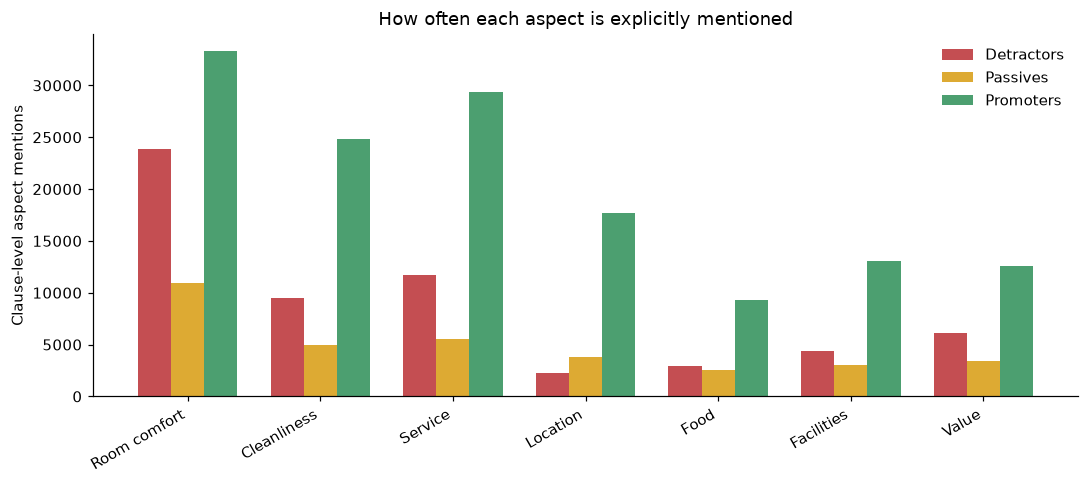

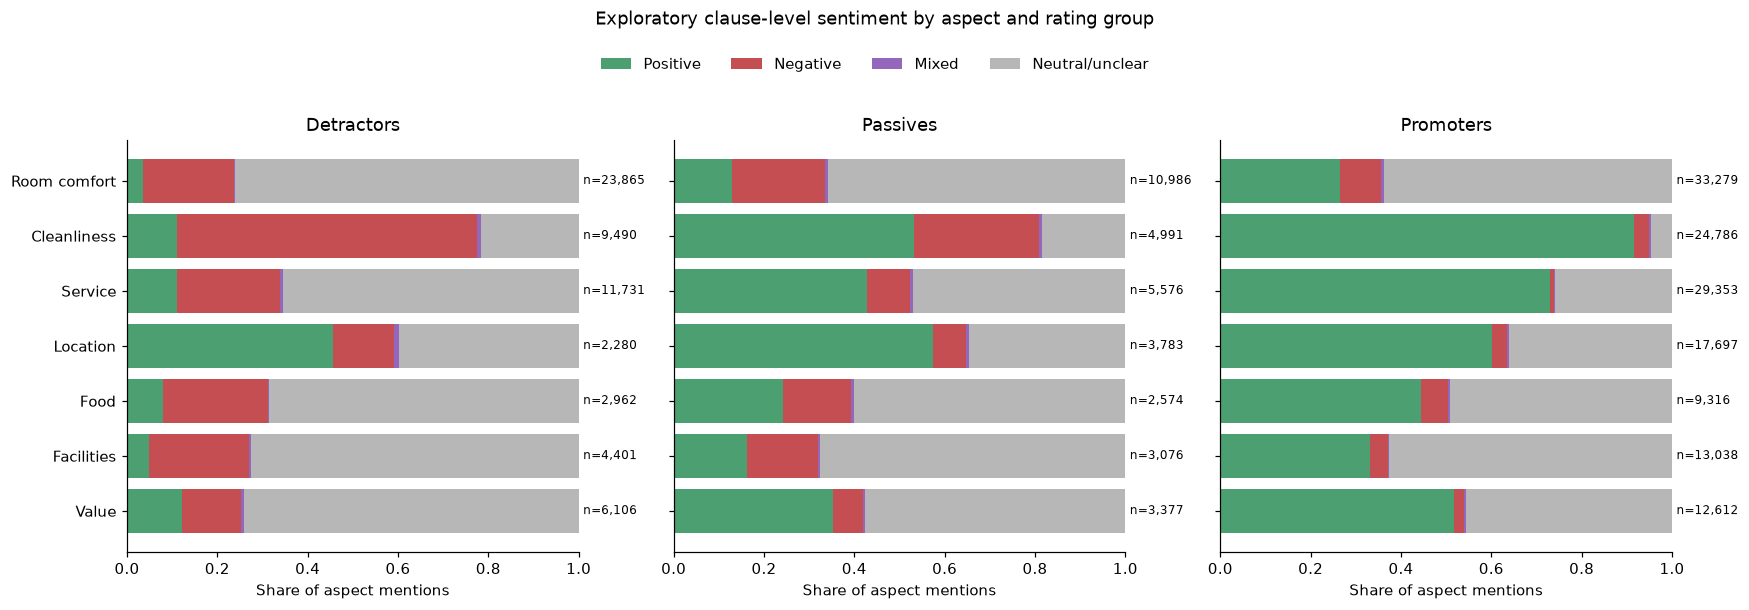

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(aspects))
width = 0.25
for gi, group in enumerate(GROUPS):
    values = [sum(counts[(group, aspect, sentiment)] for sentiment in sentiments)
              for aspect in aspects]
    ax.bar(x + (gi-1)*width, values, width, label=group, color=GROUP_COLORS[group])
ax.set_xticks(x, aspects, rotation=30, ha="right")
ax.set(ylabel="Clause-level aspect mentions", title="How often each aspect is explicitly mentioned")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

sentiment_colors = {"Positive": "#4c9f70", "Negative": "#c44e52",
                    "Mixed": "#9467bd", "Neutral/unclear": "#b7b7b7"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, group in zip(axes, GROUPS):
    left = np.zeros(len(aspects))
    totals = [sum(counts[(group, aspect, s)] for s in sentiments) for aspect in aspects]
    for sentiment in sentiments:
        values = [counts[(group, aspect, sentiment)] / total if total else 0
                  for aspect, total in zip(aspects, totals)]
        ax.barh(aspects, values, left=left, color=sentiment_colors[sentiment],
                label=sentiment)
        left += values
    ax.set(title=group, xlabel="Share of aspect mentions", xlim=(0, 1))
    for y, total in enumerate(totals):
        ax.text(1.01, y, f"n={total:,}", va="center", fontsize=8)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Exploratory clause-level sentiment by aspect and rating group", y=1.1)
plt.tight_layout(); plt.show()


## 11. Print an interpretable results table and an audit sample

For each rating group and aspect, report the mention count plus the four label percentages. A sample of predictions from the **actual Agoda reviews** is printed for human audit. Do not read the rule-based percentages as model accuracy. To measure accuracy, independently annotate a held-out sample of clauses with their aspect(s) and sentiment, then calculate aspect detection precision/recall/F1 and sentiment macro-F1. Ambiguous spans, code-switching, and negation should be represented in that sample.


In [22]:
print("Group | Aspect | Mentions | Positive | Negative | Mixed | Neutral/unclear")
for group in GROUPS:
    for aspect in aspects:
        n = sum(counts[(group, aspect, s)] for s in sentiments)
        if not n:
            continue
        values = [counts[(group, aspect, s)] / n for s in sentiments]
        print(f"{group} | {aspect} | {n:,} | " + " | ".join(f"{v:.1%}" for v in values))

# This is an audit queue, not a gold-label evaluation set.
audit_rng = random.Random(SEED)
for sentiment in sentiments:
    pool = [m for m in mentions if m["sentiment"] == sentiment]
    sample_items = audit_rng.sample(pool, min(5, len(pool)))
    print(f"\nPredicted {sentiment}: {len(pool):,} mentions; sample for manual review")
    for item in sample_items:
        print(f"  [{item['group']} / {item['aspect']}] {item['clause'][:180]}")


Group | Aspect | Mentions | Positive | Negative | Mixed | Neutral/unclear
Detractors | Room comfort | 23,865 | 3.6% | 20.0% | 0.3% | 76.1%
Detractors | Cleanliness | 9,490 | 11.0% | 66.5% | 0.9% | 21.6%
Detractors | Service | 11,731 | 11.1% | 22.7% | 0.7% | 65.4%
Detractors | Location | 2,280 | 45.7% | 13.5% | 1.0% | 39.8%
Detractors | Food | 2,962 | 7.9% | 23.3% | 0.3% | 68.5%
Detractors | Facilities | 4,401 | 4.8% | 22.2% | 0.4% | 72.6%
Detractors | Value | 6,106 | 12.2% | 13.0% | 0.6% | 74.2%
Passives | Room comfort | 10,986 | 12.9% | 20.5% | 0.7% | 65.9%
Passives | Cleanliness | 4,991 | 53.2% | 27.7% | 0.7% | 18.4%
Passives | Service | 5,576 | 42.8% | 9.6% | 0.7% | 46.9%
Passives | Location | 3,783 | 57.4% | 7.4% | 0.5% | 34.7%
Passives | Food | 2,574 | 24.3% | 15.0% | 0.7% | 60.1%
Passives | Facilities | 3,076 | 16.2% | 15.7% | 0.5% | 67.7%
Passives | Value | 3,377 | 35.4% | 6.5% | 0.5% | 57.6%
Promoters | Room comfort | 33,279 | 26.4% | 9.1% | 0.8% | 63.7%
Promoters | Cleanliness

## Interpretation and next validation step

**What the notebook supports:** one common LDA topic space, topic prevalence by rating group, and exploratory aspect–polarity counts from actual clauses. **What it does not establish:** that every topic equals a service aspect, or that the lexical sentiment rules are accurate on Agoda reviews. Inspect the audit sample and annotate a stratified held-out set before making strong claims. Keep `Mixed` separate from `Neutral/unclear`; the latter often means the rules did not recognize an opinion. The preprocessing removed reviews classified as non-Vietnamese/ambiguous and clauses without surviving LDA tokens, and the original scraper sampled several Agoda sort orders, so corpus-level percentages may not represent all Agoda guests.

In the final report, compare this notebook with Experiment A as a **methodological extension**. The baseline does not produce aspect-level sentiment predictions, so do not claim a direct improvement in sentiment accuracy without a shared labeled evaluation task.
